# 01 · Análisis Exploratorio de Datos (EDA) de la data cruda y su transformación

Este notebook trabaja con la data **cruda** extraída de yahoo finance y se analizan los siguientes aspectos: 
- Calidad y limpieza de los de datos: negativos, faltantes, análisis estadístico de series temporales.
- División de la data en entrenamiento, validación y test.
- Transformación: Mediante pruebas estadísticas como ADF, Correlation Spearman, etc se determina el tipo de transfromación para cada variable (retornos logarítmicos o diferencias).

## 0. Configuración

In [43]:
import sys
from pathlib import Path
# La raíz del proyecto es la carpeta que contiene `src/` (funciona se ejecute desde la raíz o desde notebooks/)
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

In [44]:
RAIZ

WindowsPath('d:/OneDrive - SUPERINTENDENCIA DE BANCOS/Escritorio/Proyecto_final_ML/proyecto_final_ml_wti')

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

import importlib

from src import config as cfg
import statsmodels.api as sm
from src import load_clean as lc
from src import eda_utils as eda
from src import download_data as dd
from src import preprocessing as pp

from pandas.tseries.holiday import USFederalHolidayCalendar, GoodFriday

In [96]:
importlib.reload(cfg)
importlib.reload(lc)
importlib.reload(dd)
importlib.reload(eda)
importlib.reload(pp)

<module 'src.preprocessing' from 'd:\\OneDrive - SUPERINTENDENCIA DE BANCOS\\Escritorio\\Proyecto_final_ML\\proyecto_final_ml_wti\\src\\preprocessing.py'>

## 1. Carga de la data cruda

In [59]:
dd.main()


Ya existe una descarga previa.
Leyendo archivo: wti_market_data_20261113.csv

Datos cargados correctamente.
Observaciones: 4233
Primera fecha: 2010-01-04
Última fecha: 2026-10-30

Archivo utilizado: D:\OneDrive - SUPERINTENDENCIA DE BANCOS\Escritorio\Proyecto_final_ML\proyecto_final_ml_wti\data\raw\wti_market_data_20261113.csv

Valores faltantes por serie:
WTI         0
WTI_High    0
WTI_Low     0
dtype: int64


,WTI,WTI_High,WTI_Low
Date,,,
2010-01-04,81.510002,81.680000,79.629997
2010-01-05,81.769997,82.000000,80.949997
2010-01-06,83.180000,83.519997,80.849998
2010-01-07,82.660004,83.360001,82.260002
2010-01-08,82.750000,83.470001,81.800003
...,...,...,...
2026-10-26,101.760002,103.129997,100.330002
2026-10-27,99.900002,102.820000,99.440002
2026-10-28,102.779999,103.550003,99.750000


In [60]:
base = lc.load_raw()
print(base.shape, base.index.min().date(), "->", base.index.max().date())
base.head()

(4233, 3) 2010-01-04 -> 2026-10-30


,WTI,WTI_High,WTI_Low
Date,,,
2010-01-04,81.510002,81.680000,79.629997
2010-01-05,81.769997,82.000000,80.949997
2010-01-06,83.180000,83.519997,80.849998
2010-01-07,82.660004,83.360001,82.260002
2010-01-08,82.750000,83.470001,81.800003


In [61]:
base.index = pd.to_datetime(base.index)
base = base.sort_index()
assert base.index.is_unique

Se extraen los precios de cierre diarios de las variables financieras consideradas en el proyecto. La base contiene 4.233 observaciones entre el 4 de enero de 2010 y el 30 de octubre de 2026. En el caso del WTI, se utiliza el símbolo CL=F de Yahoo Finance, que corresponde a una serie continua de futuros. La fecha identifica la sesión de negociación y el valor de WTI representa el precio de cierre, en dólares por barril, del contrato de futuros que la serie sigue en esa fecha. El contrato específico y su mes de entrega pueden cambiar a lo largo del tiempo.


| Variable | Unidades | Descripción |
|---|---|---|
| `Date` | Fecha (AAAA-MM-DD) | Fecha de la sesión de negociación a la que corresponde el precio de cierre observado. Permite ordenar cronológicamente las series y sincronizar las variables financieras. |
| `WTI` | USD por barril (USD/bbl) | Precio de cierre de la serie continua de futuros de petróleo crudo West Texas Intermediate (WTI), descargada de Yahoo Finance mediante el símbolo CL=F. Representa la cotización del contrato de futuros que la serie sigue en esa fecha; no es necesariamente el precio spot ni el precio de entrega física inmediata. |


Entonces, para leer la información de la data se debe leer de la siguiente forma:


***El día X del mes Y del año Z, el precio de cierre reportado para la serie continua de futuros de petróleo crudo WTI (CL=F) fue de $M por barril.***

La fecha corresponde a la sesión de negociación. El precio es el cierre del contrato que la serie continua sigue en esa fecha; no significa necesariamente que se comprara petróleo físico a ese precio.

Un contrato de futuros es un acuerdo estandarizado para comprar o vender una cantidad determinada de petróleo en un mes futuro, bajo condiciones definidas por el mercado. Los contratos tienen distintos meses de entrega y se negocian diariamente. Como CL=F es una serie continua, va siguiendo contratos sucesivos conforme se acercan sus vencimientos; por eso, cada observación diaria no necesariamente corresponde al mismo contrato.

La base descargada contiene tres variables de la serie continua de futuros WTI (CL=F): el precio de cierre (WTI) y los precios máximo (WTI_High) y mínimo (WTI_Low) negociados en cada sesión. El análisis exploratorio de esta sección (calidad de datos, huecos en el calendario, saltos extremos, resumen estadístico y transformación a retornos) se aplica únicamente al precio de cierre WTI, que es la serie a partir de la cual se construyen los retornos logarítmicos.

Los precios WTI_High y WTI_Low no se analizan como series independientes: solo se verifica su consistencia (ausencia de nulos, valores positivos y que se cumpla WTI_Low ≤ WTI ≤ WTI_High), ya que su única función es calcular el estimador de volatilidad de Parkinson:
 
 $\sigma^2_{P,t} = \left[100 \cdot \ln(\text{High}_t/\text{Low}_t)\right]^2 / (4 \ln 2)$, 
 
 que mide la amplitud del movimiento del precio dentro de cada día. Este indicador se incorpora a la tabla de modelado junto con los retornos, se divide con los mismos cortes temporales y se utiliza como variable objetivo (proxy de la varianza diaria) para entrenar y evaluar los dos modelos.

### 1.1 Calidad de datos faltantes,ceros y negativos

In [62]:
# El índice debe ser datetime, ordenado y sin duplicados
print(base.index.dtype, base.index.is_monotonic_increasing, base.index.duplicated().sum())

datetime64[us] True 0


In [63]:
eda.chequeo_calidad(base).T

,WTI,WTI_High,WTI_Low
min,-37.630001,13.69,-40.32
n_<=0,1.000000,0.00,2.00
n_inf,0.000000,0.00,0.00
n_nulos,0.000000,0.00,0.00
n_dias_sin_cambio,14.000000,11.00,9.00


El chequeo de calidad de la serie WTI muestra que el valor mínimo es −$37,63 por barril y que existe un solo valor menor o igual a cero. No se detectan valores infinitos ni datos nulos. También se identifican 14 días sin variación en el precio, que conviene revisar para confirmar que sean observaciones legítimas y no valores repetidos por algún problema de descarga o relleno.

Para el caso de WTI_High el mínimo observado es $13,69 por barril y no hay valores menores o iguales a cero. No presenta valores nulos ni infinitos. Se identifican 11 días sin variación.

En el caso de WTI_Low el mínimo es −$40,32 por barril y hay 2 observaciones menores o iguales a cero. No presenta valores nulos ni infinitos. Se registran 9 días sin variación. Los valores negativos podrían corresponder a condiciones excepcionales del mercado; antes de corregirlos o eliminarlos, es recomendable revisar sus fechas y contrastarlos con la fuente.


In [64]:
lc.summarize_negative_values(base)

,cantidad,porcentaje
WTI_Low,2,0.05
WTI,1,0.02
WTI_High,0,0.00


In [65]:
lc.rows_with_negative_values(base)

,WTI,WTI_High,WTI_Low
Date,,,
2020-04-20,-37.630001,17.85,-40.32
2020-04-21,10.010000,13.86,-16.74


Se analizan los valores negativos que pudieran afectar las transformaciones de retornos y se encuentra un valor negativo en la serie WTI de los precios y dos valores negativos en WTI_Low, correspondientes al 20 y al 21 de abril de 2020. 

Estos  valores se relacionan con las condiciones excepcionales del mercado petrolero durante la pandemia de COVID-19: la caída abrupta de la demanda y el exceso de oferta que elevaron los inventarios y generaron preocupación por la disponibilidad de almacenamiento en Cushing, Oklahoma, punto de entrega del contrato WTI. Además, el contrato de futuros con entrega en mayo estaba próximo a vencer. Algunos operadores que no podían o no querían recibir físicamente el petróleo vendieron sus posiciones a precios negativos, pagando efectivamente para salir del contrato. El cierre de ese contrato fue de −$37,63 por barril.

Por tanto, los valores negativos no deben interpretarse como un error de los datos ni como que todos los tipos de petróleo se vendieron a un precio negativo: corresponde a un contrato específico de futuros de WTI en una situación extraordinaria, cerca de su vencimiento.

Ahora, se van a analizar los días que no muestran grandes variaciones o cambios.

In [66]:
eda.dias_sin_cambio(base)

,serie,fecha_previa,fecha,valor
0,WTI,2010-07-23,2010-07-26,78.980003
1,WTI,2010-11-10,2010-11-11,87.809998
2,WTI,2017-09-14,2017-09-15,49.889999
3,WTI,2018-05-16,2018-05-17,71.489998
4,WTI,2018-11-15,2018-11-16,56.459999
5,WTI,2019-12-04,2019-12-05,58.430000
6,WTI,2020-02-14,2020-02-18,52.049999
7,WTI,2020-04-15,2020-04-16,19.870001
8,WTI,2020-08-17,2020-08-18,42.889999
9,WTI,2021-09-15,2021-09-16,72.610001


La U.S. Energy Information Administration (EIA) (https://www.eia.gov/dnav/pet/hist/RCLC1D.htm) es una agencia independiente del Departamento de Energía de Estados Unidos que recopila y publica información sobre los mercados energéticos. Al comparar los precios de la serie WTI con los valores de futuros publicados por la EIA, no se encontraron errores anormales ni indicios de errores de digitación. Los días sin cambio corresponden a valores de cierre repetidos entre sesiones consecutivas; estos pueden deberse a condiciones del mercado o a diferencias en el registro y publicación de los datos, por lo que no se consideran errores sin evidencia adicional.

### 1.2 Huecos en el calendario

A continuación, se toma la fecha inicial y final de la serie base y se generan las fechas de los feriados federales de Estados Unidos dentro de ese periodo y añade las fechas de Viernes Santo. Luego combina ambas listas y las compara con el índice de base para identificar cuáles de esos feriados aparecen como fechas de observación en la serie. 

Esta comparación ayuda a revisar el calendario, aunque no confirma por sí sola los días oficiales de negociación de los futuros WTI.

In [67]:
inicio = base.index.min()
fin = base.index.max()

feriados_fed = USFederalHolidayCalendar().holidays(
    start=inicio,
    end=fin,
)

viernes_santo = GoodFriday.dates(inicio, fin)

feriados = feriados_fed.union(viernes_santo).sort_values()

print("Feriados generados:", len(feriados))

Feriados generados: 189


In [68]:
base.index = pd.to_datetime(base.index).normalize()

In [69]:
# bdate_range() genera un rango de fechas considerando solo días hábiles (lunes a viernes)
# genera primero todas las fechas de lunes a viernes desde la fecha mínima hasta la máxima de 
# y con .difference(base.index), quita las fechas que sí están en el índice de base. 
# El resultado son las fechas de lunes a viernes que no aparecen en la base.

faltan = pd.bdate_range(base.index.min(), base.index.max()).difference(base.index)
print(len(faltan)); faltan[:20]

157


DatetimeIndex(['2010-01-18', '2010-02-15', '2010-04-02', '2010-05-31',
               '2010-07-05', '2010-09-06', '2010-11-25', '2010-12-24',
               '2011-01-17', '2011-02-21', '2011-04-22', '2011-05-30',
               '2011-07-04', '2011-09-05', '2011-11-24', '2011-12-26',
               '2012-01-02', '2012-01-16', '2012-02-20', '2012-04-06'],
              dtype='datetime64[us]', freq=None)

In [70]:
faltan_sin_feriados = faltan.difference(feriados)

print(len(faltan_sin_feriados))
faltan_sin_feriados[:20]

3


DatetimeIndex(['2012-10-29', '2012-10-30', '2018-12-05'],
              dtype='datetime64[us]', freq=None)

In [71]:
faltan_sin_feriados_df = pd.DataFrame({
    "fecha": faltan_sin_feriados,
})

faltan_sin_feriados_df["dia_semana"] = (
    faltan_sin_feriados_df["fecha"].dt.day_name()
)

In [72]:
faltan_sin_feriados_df

,fecha,dia_semana
0,2012-10-29,Monday
1,2012-10-30,Tuesday
2,2018-12-05,Wednesday


Una vez quitados los feriados federales de USA, se encontró que existen 3 días laborales que se no son feriados y que deben reportar información de mercado dentro de la serie WTI en la que vamos a trabajar, por lo que vamos a validar si aquellos días se encuentran o no en nuestra serie. 

In [73]:

fechas_a_revisar = pd.DatetimeIndex(faltan_sin_feriados_df["fecha"])

faltantes_presentes = fechas_a_revisar.intersection(base.index)

print(f"Fechas que sí están en base: {len(faltantes_presentes)}")
display(faltantes_presentes)

Fechas que sí están en base: 0


DatetimeIndex([], dtype='datetime64[us]', freq=None)

Como se puede observar, ninguna de las tres fechas aparecen en la base madre en la que trabajaremos, y esto se debe a que: 

- Lunes 29 y martes 30 de octubre de 2012 (Huracán Sandy). La Bolsa de Nueva York (NYSE) y demás mercados estadounidenses cerraron sus operaciones por el impacto del huracán Sandy en la costa este. Fue la primera vez desde 1888 que los mercados cerraban durante dos días consecutivos debido a condiciones climáticas.
- Miércoles 5 de diciembre de 2018 (Duelo nacional por George H. W. Bush). El gobierno federal y los principales mercados bursátiles de Estados Unidos suspendieron sus actividades para observar el Día Nacional de Luto tras el fallecimiento del expresidente George H. W. Bush.

### 1.3 Saltos extremos

In [86]:
eda.saltos_extremos(base[["WTI"]]).T

,0,1,2,3,4
serie,WTI,WTI,WTI,WTI,WTI
fecha_previa,2020-04-21,2020-03-06,2020-04-24,2020-04-17,2020-04-20
fecha,2020-04-22,2020-03-09,2020-04-27,2020-04-20,2020-04-21
precio_previo,10.01,41.279999,16.940001,18.27,-37.630001
precio_actual,13.78,31.129999,12.78,-37.630001,10.01
cambio,3.77,-10.15,-4.160001,-55.900002,47.640001
cambio_pct,37.662332,-24.588178,-24.557265,-305.966065,-126.601116
log_var_abs,0.319634,0.282206,0.281796,NaN,NaN


Todos los saltos extremos  se concentran en el año 2020, durante el choque petrolero de la pandemia: la demanda cayó bruscamente, hubo exceso de oferta y aumentó la preocupación por la capacidad de almacenamiento. El caso más excepcional es el del 20 de abril, cuando el futuro WTI próximo a vencer cerró en −$37,63 por barril; el cambio desde el cierre previo de $18,27 fue de −$55,90. Los movimientos de los días siguientes reflejan el rebote desde ese episodio y la alta volatilidad de esos días.

Los porcentajes alrededor del valor negativo deben interpretarse con cuidado: al pasar de un precio negativo a uno positivo, el porcentaje convencional puede resultar engañoso. Para esos días es más claro comparar los precios y el cambio en dólares por barril. Estos saltos son extremos, pero coherentes con un periodo de mercado excepcional; por sí solos no prueban errores de digitación ni identifican un cambio de contrato.

In [87]:
top10, excluidos = eda.top_movimientos_diarios(base[["WTI"]])

display(top10)

,día,cierre_anterior,cierre,retorno_log_%,retorno_simple_%
2020-03-09,Monday,41.28,31.13,-28.22,-24.59
2020-03-18,Wednesday,26.95,20.37,-27.99,-24.42
2020-03-19,Thursday,20.37,25.22,21.36,23.81
2020-04-02,Thursday,20.31,25.32,22.05,24.67
2020-04-22,Wednesday,10.01,13.78,31.96,37.66
2020-04-23,Thursday,13.78,16.50,18.01,19.74
2020-04-27,Monday,16.94,12.78,-28.18,-24.56
2020-04-29,Wednesday,12.34,15.06,19.92,22.04
2020-04-30,Thursday,15.06,18.84,22.39,25.10
2020-05-05,Tuesday,20.39,24.56,18.61,20.45


Tu tabla muestra que los 10 mayores movimientos logarítmicos calculables se concentran entre marzo y mayo de 2020. Hay caídas fuertes, como el −28,22 % del 9 de marzo, y rebotes, como el +31,96 % del 22 de abril. Esa concentración refleja la volatilidad extraordinaria del mercado petrolero durante la pandemia, cuando se desplomó la demanda y aumentó la preocupación por el almacenamiento.

### 1.4 Resumen estadístico

In [88]:
base.loc[(base["WTI_Low"] > base["WTI"]) | (base["WTI"] > base["WTI_High"])]

,WTI,WTI_High,WTI_Low
Date,,,


En ninguna fila del dataframe se incumple que $WTI_{LOW}\leq WTI \leq WTI_{HIGH}$

In [89]:
eda.descriptivos_precios(base[["WTI"]]).T

serie,WTI
n,4233
media,72.215195
std,20.731412
CV,0.287078
min,-37.630001
fecha_min,2020-04-20
p25,55.91
mediana,72.199997
p75,89.230003
max,123.699997


In [90]:
display(eda.estadisticos_por_anio(base, "WTI"))

,count,mean,std,min,median,max
Date,,,,,,
2010,252,79.61,5.19,68.01,79.74,91.51
2011,252,95.11,8.08,75.67,95.83,113.93
2012,250,94.21,7.67,77.69,92.70,109.77
2013,252,98.05,5.43,86.68,96.61,110.53
2014,252,92.91,13.37,53.27,97.74,107.26
2015,252,48.76,6.79,34.73,47.95,61.43
2016,250,43.44,6.70,26.21,45.06,54.06
2017,251,50.85,3.91,42.53,50.42,60.42
2018,251,64.95,6.68,42.53,66.22,76.41


### 1.5 Gráfica de la serie cruda

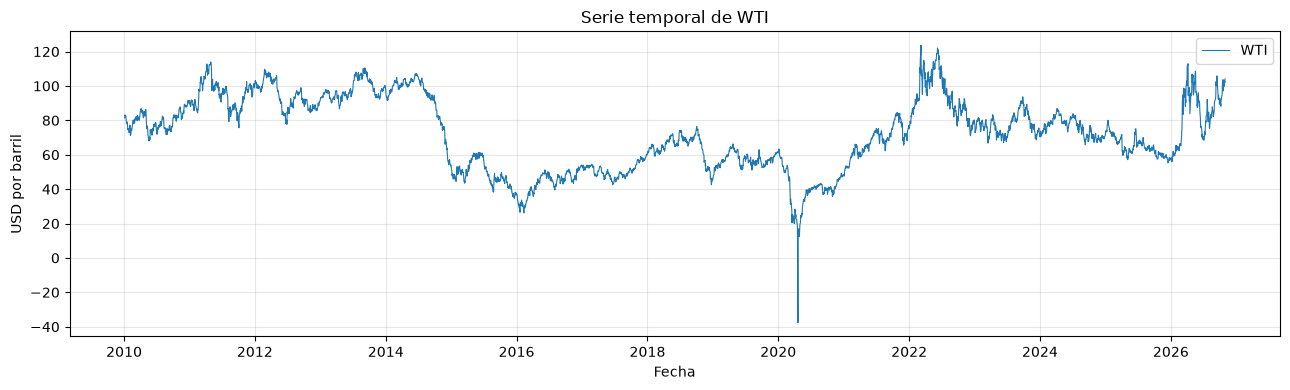

In [91]:
eda.graficar_serie_temporal(base["WTI"], nombre="WTI", unidad="USD por barril")

### 1.6 Tranformación de la serie

En la sección 1.1 se identificaron dos precios negativos: el 20 de abril de 2020 (−$37,63), mientras que el 21 de abril cerró en $10,01, pero el mínimo intradía (WTI_Low) fue negativo en ambas fechas: −$40,32 el 20 de abril y −$16,74 el 21 de abril. 

Como el logaritmo no está definido para valores no positivos, se excluye el cierre del 20 de abril del cálculo de retornos. El retorno del 21 de abril se calcula respecto al último cierre positivo disponible, el 17 de abril; por tanto, refleja el cambio acumulado durante ese intervalo, no un retorno de un solo día.

producto del vencimiento del contrato de mayo y la falta de capacidad de almacenamiento. Como el logaritmo no está definido para valores ≤ 0, se elimina esta observación (1 de 4,233). El retorno del 21-abr-2020 se calcula respecto al 17-abr-2020 y se conserva como evento extremo real.

La serie de precios se transforma en retornos logarítmicos diarios (en %):


$$r_t = 100 \cdot \ln\left(\frac{P_t}{P_{t-1}}\right)$$

Se elige esta transformación porque:

- los retornos logarítmicos no dependen de la escala del precio y se interpretan como variación porcentual aproximada;
- son aditivos en el tiempo (el retorno de varios días es la suma de los retornos diarios);
- son la variable estándar en los modelos ARIMA/GARCH y en la literatura de pronóstico financiero.

**Estimador de volatilidad de Parkinson**

La volatilidad diaria no se observa directamente: solo se observan los precios. Para entrenar y evaluar los modelos se necesita una medida observable de la varianza de cada día, es decir, un **proxy**. La opción más simple es el retorno al cuadrado, $r_t^2$, pero es muy ruidosa porque solo usa el precio de cierre: un día con fuertes oscilaciones que termina cerca del cierre anterior tiene $r_t^2 \approx 0$, aunque haya sido muy volátil.

El estimador de Parkinson aprovecha la información de toda la sesión a través del rango entre el precio máximo y el mínimo del día:

$$\sigma^2_{P,t} = \frac{\left[100 \cdot \ln\left(\dfrac{\text{High}_t}{\text{Low}_t}\right)\right]^2}{4 \ln 2}$$

donde $\text{High}_t$ y $\text{Low}_t$ son los precios máximo y mínimo negociados el día $t$. El factor $4\ln 2$ corrige el sesgo del rango para que, bajo el supuesto de que el precio sigue un movimiento browniano sin tendencia, el estimador sea insesgado para la varianza diaria. Se multiplica por 100 para que quede en $\%^2$, en la misma escala que $r_t^2$.

Se elige este proxy porque:

- **es más eficiente que $r_t^2$**: al usar el rango intradía tiene una varianza mucho menor (Parkinson muestra que es alrededor de cinco veces más eficiente que el estimador basado solo en cierres), por lo que mide la volatilidad de cada día con menos ruido;
- **refleja la amplitud real del movimiento del día**, no solo el resultado neto entre dos cierres;
- **reduce el problema de evaluar con un proxy imperfecto**: un proxy menos ruidoso permite distinguir mejor qué modelo pronostica con mayor precisión [6].

Limitaciones a considerar:

- supone negociación continua y sin saltos, por lo que **no captura el movimiento entre el cierre de un día y la apertura del siguiente**. En los futuros WTI el efecto es menor que en acciones, porque se negocian casi las 24 horas, pero puede subestimar la varianza en días con brechas de apertura;

- supone que el precio no tiene tendencia dentro del día, algo razonable para horizontes diarios.

In [92]:
base1,filas_eliminadas=eda.drop_nonpositive_rows(base)

In [93]:
base1

,WTI,WTI_High,WTI_Low
Date,,,
2010-01-04,81.510002,81.680000,79.629997
2010-01-05,81.769997,82.000000,80.949997
2010-01-06,83.180000,83.519997,80.849998
2010-01-07,82.660004,83.360001,82.260002
2010-01-08,82.750000,83.470001,81.800003
...,...,...,...
2026-10-26,101.760002,103.129997,100.330002
2026-10-27,99.900002,102.820000,99.440002
2026-10-28,102.779999,103.550003,99.750000


In [94]:
filas_eliminadas

,WTI,WTI_High,WTI_Low
Date,,,
2020-04-20,-37.630001,17.85,-40.32
2020-04-21,10.010000,13.86,-16.74


In [28]:
# La decisión vive en src/config.py (TRANSF). Si cambia el diagnóstico, se edita allí.
pd.Series(cfg.transf, name="transformación")

WTI    logret
Name: transformación, dtype: str

In [97]:
base_ret=pp.build_returns(base1)

In [99]:
base_ret = pp.build_returns(base1, parkinson={"WTI_park": ("WTI_High", "WTI_Low")})

In [100]:
base_ret

,WTI,WTI_park
Date,,
2010-01-05,0.318465,0.599044
2010-01-06,1.709655,3.807394
2010-01-07,-0.627108,0.636423
2010-01-08,0.108816,1.473154
2010-01-11,-0.278337,2.075756
...,...,...
2026-10-26,-1.472976,2.732662
2026-10-27,-1.844742,4.029657
2026-10-28,2.842107,5.041605


## 2.División temporal de los datos

En series de tiempo no se puede dividir la muestra de forma aleatoria (k-fold clásico), porque el modelo usaría observaciones del futuro para predecir el pasado (fuga de información). Por eso la división respeta el orden cronológico:

- Train/Validation o Desarrollo (2010–2024): se usa para el diagnóstico de la serie, la optimización de hiperparámetros y la comparación estadística, mediante validación walk-forward.
- Test final (2025–oct 2026): se reserva y no se utiliza hasta la evaluación final de ambos modelos.

El periodo de desarrollo abarca de enero de 2010 a diciembre de 2024. El test final comprende de enero de 2025 a octubre de 2026 y funciona como verificación fuera de muestra: ambos modelos del proyecto se entrenarán con todo el desarrollo y se evalúan una sola vez en este periodo.

In [101]:
dev_ini=cfg.DEV_INI
dev_fin=cfg.DEV_FIN
test_ini=cfg.TEST_INI
test_fin=cfg.TEST_FIN

In [102]:
dev=base_ret.loc[dev_ini:dev_fin]
test=base_ret.loc[test_ini:test_fin]

In [103]:
# Verificaciones
assert dev.index.max() < test.index.min()          # sin traslape
assert len(dev) + len(test) == len(base_ret)       # no se pierden observaciones

### 2.1 Validación walk-forward o Time Cross Validation 

Al ser una serie de tiempo indexada con las fechas diarias de negociación y con los retornos calculados, se empleará la validación walk forward con ventana expansiva o Time Series Cross-Validation (TSCV) en machine learning.
en cada fold, el modelo se entrena con todos los datos anteriores al bloque de validación y se evalúa en los 12 meses siguientes.

El intervalo de desarrollo (2010-2024) contiene el train y la validación, los cuales se van alternando en cada fold, es decir: 
- Train: todo lo anterior al bloque de validación de ese fold.
- Validación: los 12 meses siguientes.

Por ejemplo: 

| Fold | Train | Validación |
|---|---|---|
| Rep 1 · Fold 1 | 2010 → 2019 | 2020 |
| Rep 1 · Fold 2 | 2010 → 2020 | 2021 |
| Rep 1 · Fold 3 | 2010 → 2021 | 2022 |
| Rep 1 · Fold 4 | 2010 → 2022 | 2023 |
| Rep 1 · Fold 5 | 2010 → 2023 | 2024 |

Una característica importante de este procedimiento es que **un mismo período puede utilizarse primero como validación y posteriormente formar parte del entrenamiento**.

Por ejemplo, el año **2020**:

- Es utilizado como **validación** en el Fold 1.
- Posteriormente pasa a formar parte del **train** en los Folds 2, 3, 4 y 5.

Por lo tanto, a diferencia de una división tradicional *train/validation*, en Time Series Cross-Validation **no existe un único conjunto de entrenamiento ni un único conjunto de validación**. Ambos van cambiando a medida que se avanza temporalmente.

Este esquema también se conoce como **Expanding Window**, porque la ventana de entrenamiento se va expandiendo en cada iteración.


```text
base_ret (2010 → oct-2026)
│
├── Desarrollo (2010 → 2024)
│   │
│   ├── Train + Validación mediante Time Series Cross-Validation
│   │   └── El train se expande y la validación avanza en el tiempo
│   │
│   └── Se utiliza para:
│       ├── EDA
│       ├── Optimización de hiperparámetros con Optuna
│       └── Comparación y selección estadística de modelos
│
└── Test final (2025 → oct-2026)
    └── Se utiliza una sola vez al final para evaluar
        el desempeño real del modelo seleccionado
```

De esta manera se respeta el orden temporal de los datos: **Pasado → Futuro**

Nunca se utiliza información futura para entrenar un modelo que será evaluado en el pasado.


![Time Series Cross-Validation](../img/imagen1.1.png)

![Time Series Cross-Validation](../img/imagen1.png)

Se obtienen bloques de validación que cubren regímenes distintos (COVID-19, recuperación de 2021, guerra en Ucrania en 2022 y años más estables). Los dos modelos se evalúan exactamente en los mismos folds.

In [105]:
FOLDS = eda.definir_folds()

# Tabla de los folds
tabla_folds = FOLDS.copy()
tabla_folds[["n_train", "n_val"]] = [
    [len(a) for a in eda.indices_fold(dev.index, f)] for f in FOLDS.itertuples()]
for c in ["train_ini", "train_fin", "val_ini", "val_fin"]:
    tabla_folds[c] = tabla_folds[c].dt.date
display(tabla_folds)

assert (FOLDS["val_fin"] <= pd.Timestamp(dev_fin)).all()   # ningún fold toca el test final


,rep,fold,train_ini,train_fin,val_ini,val_fin,n_train,n_val
0,1,1,2010-01-01,2019-12-31,2020-01-01,2020-12-31,2513,251
1,1,2,2010-01-01,2020-12-31,2021-01-01,2021-12-31,2764,252
2,1,3,2010-01-01,2021-12-31,2022-01-01,2022-12-31,3016,251
3,1,4,2010-01-01,2022-12-31,2023-01-01,2023-12-31,3267,250
4,1,5,2010-01-01,2023-12-31,2024-01-01,2024-12-31,3517,252
5,2,1,2010-01-01,2019-06-30,2019-07-01,2020-06-30,2385,251
6,2,2,2010-01-01,2020-06-30,2020-07-01,2021-06-30,2636,252
7,2,3,2010-01-01,2021-06-30,2021-07-01,2022-06-30,2888,252
8,2,4,2010-01-01,2022-06-30,2022-07-01,2023-06-30,3140,251
9,2,5,2010-01-01,2023-06-30,2023-07-01,2024-06-30,3391,250


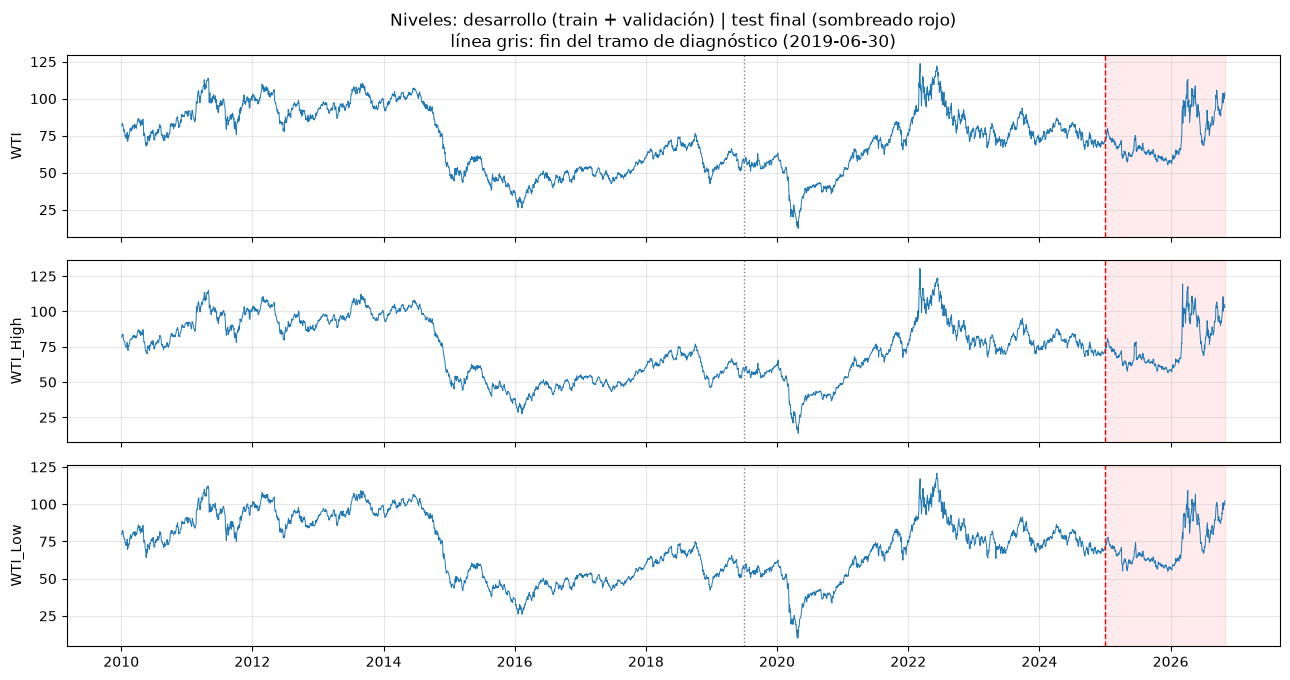

In [106]:
eda.graficar_niveles_con_cortes(base1)

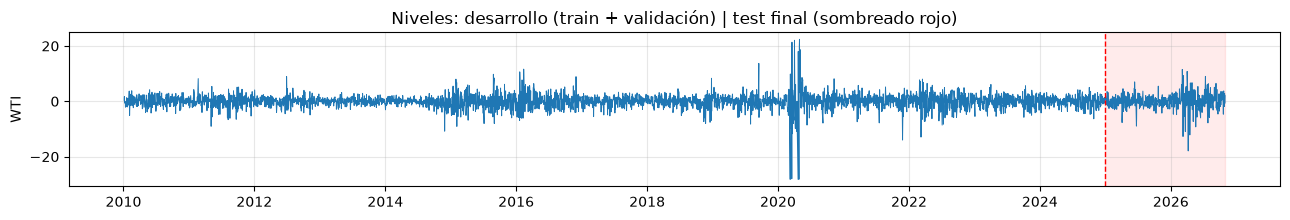

In [107]:
eda.graficar_niveles_con_cortes(base_ret,columnas=["WTI"], mostrar_eda=False)

### 2.2 Tramo para diagnósticos: 2010-2019 (train del primer fold)

Las pruebas que orientan la elección del modelo base (estacionariedad, estacionalidad, ACF/PACF, Ljung-Box y ARCH-LM) se aplicarán al tramo enero 2010 – junio 2019, el cual corresponde al periodo de entrenamiento más corto de todos los folds (Rep 2 · Fold 1). 

Así, ninguna decisión de modelado usa información de los bloques de validación ni del test final.

In [108]:
EDA_FIN = FOLDS["train_fin"].min()          # = 2019-06-30, el train más corto
train_ret = base_ret.loc[:EDA_FIN]

print(f"Tramo de diagnóstico: {train_ret.index.min().date()} → {train_ret.index.max().date()} "
      f"({len(train_ret)} obs, {100*len(train_ret)/len(dev):.1f}% del desarrollo)")
assert train_ret.index.max() < FOLDS["val_ini"].min()   # no toca ninguna validación

Tramo de diagnóstico: 2010-01-05 → 2019-06-28 (2385 obs, 63.3% del desarrollo)


In [109]:
train_ret

,WTI,WTI_park
Date,,
2010-01-05,0.318465,0.599044
2010-01-06,1.709655,3.807394
2010-01-07,-0.627108,0.636423
2010-01-08,0.108816,1.473154
2010-01-11,-0.278337,2.075756
...,...,...
2019-06-24,0.815059,2.358784
2019-06-25,-0.120971,2.882069
2019-06-26,2.644978,1.681142


El tramo de diagnóstico (EDA) comprende desde el 5 de enero de 2010 hasta el 28 de junio de 2019, con un total de 2.385 observaciones, que representan el 63,3 % del conjunto de desarrollo (2010–2024).

Este período se utiliza para analizar el comportamiento histórico de las series financieras, identificar tendencias, volatilidad, estacionariedad, valores atípicos y relaciones entre variables, antes de realizar la validación temporal y el entrenamiento de los modelos predictivos.

In [113]:

out = RAIZ / "data" / "processed"
out.mkdir(parents=True, exist_ok=True)
dev.to_csv(out / "train_validation.csv")       # precio sin el 20-abr-2020
test.to_csv(out / "test.csv")
FOLDS.to_csv(out / "folds.csv", index=False)

In [114]:
FOLDS

,rep,fold,train_ini,train_fin,val_ini,val_fin
0,1,1,2010-01-01,2019-12-31,2020-01-01,2020-12-31
1,1,2,2010-01-01,2020-12-31,2021-01-01,2021-12-31
2,1,3,2010-01-01,2021-12-31,2022-01-01,2022-12-31
3,1,4,2010-01-01,2022-12-31,2023-01-01,2023-12-31
4,1,5,2010-01-01,2023-12-31,2024-01-01,2024-12-31
5,2,1,2010-01-01,2019-06-30,2019-07-01,2020-06-30
6,2,2,2010-01-01,2020-06-30,2020-07-01,2021-06-30
7,2,3,2010-01-01,2021-06-30,2021-07-01,2022-06-30
8,2,4,2010-01-01,2022-06-30,2022-07-01,2023-06-30
9,2,5,2010-01-01,2023-06-30,2023-07-01,2024-06-30
